In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [2]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['species'] = iris.target

print("First Five Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nSpecies Names:")
print(iris.target_names)

print("\nMissing Values:")
print(df.isnull().sum())

First Five Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset Shape:
(150, 5)

Species Names:
['setosa' 'versicolor' 'virginica']

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [3]:
X = df.drop('species', axis=1)

y = df['species']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target Values:
0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


In [5]:
# Create Gaussian Naive Bayes model
model = GaussianNB()

# Train the model
model.fit(X_train, y_train)

print("Bayesian Classifier Trained Successfully!")

Bayesian Classifier Trained Successfully!


In [6]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [7]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9666666666666667
Accuracy Percentage: 96.66666666666667 %


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


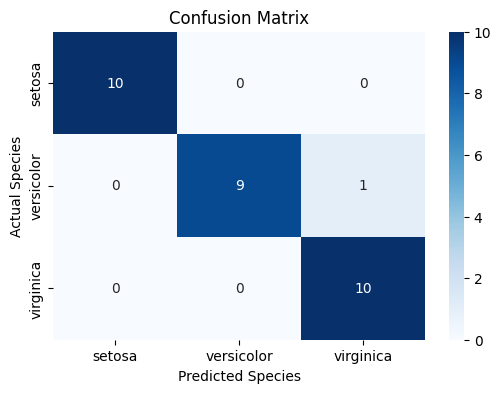

In [8]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.title("Confusion Matrix")

plt.show()

In [9]:
precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

print("Precision:", precision)

print("Recall:", recall)

Precision: 0.9696969696969696
Recall: 0.9666666666666667


In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [11]:
# New flower measurements
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict species
prediction = model.predict(new_flower)

print("Predicted Flower Species:", iris.target_names[prediction[0]])

Predicted Flower Species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


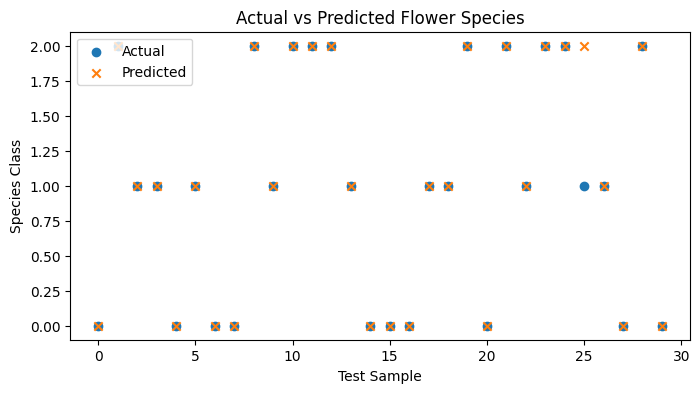

In [12]:
plt.figure(figsize=(8, 4))

plt.scatter(
    range(len(y_test)),
    y_test,
    label='Actual',
    marker='o'
)

plt.scatter(
    range(len(y_pred)),
    y_pred,
    label='Predicted',
    marker='x'
)

plt.xlabel("Test Sample")
plt.ylabel("Species Class")

plt.title("Actual vs Predicted Flower Species")

plt.legend()

plt.show()